In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(r"C:\Users\USER\fraud-detection\data\creditcard.csv")

print("Shape:", df.shape)
print("\nFirst 5 rows:")
df.head()

Shape: (284807, 31)

First 5 rows:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
print("Class counts:")
print(df["Class"].value_counts())

print("\nClass proportion:")
print(df["Class"].value_counts(normalize=True))

print("\nFraud rate: {:.4%}".format(df["Class"].mean()))

Class counts:
Class
0    284315
1       492
Name: count, dtype: int64

Class proportion:
Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64

Fraud rate: 0.1727%


In [5]:
print("Missing values total:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes.value_counts())

Missing values total: 0
Duplicate rows: 1081

Data types:
float64    30
int64       1
Name: count, dtype: int64


In [6]:
print("Amount stats:")
print(df["Amount"].describe())

print("\nAmount stats by class:")
print(df.groupby("Class")["Amount"].describe())

Amount stats:
count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64

Amount stats by class:
          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      284315.0   88.291022  250.105092  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.211321  256.683288  0.0  1.00   9.25  105.89   2125.87


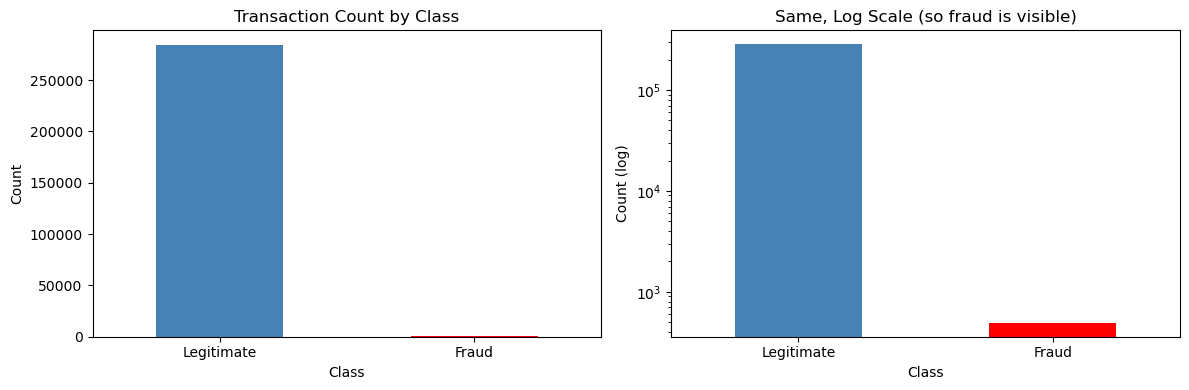

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

df["Class"].value_counts().plot(
    kind="bar", ax=ax[0], color=["steelblue", "red"]
)
ax[0].set_title("Transaction Count by Class")
ax[0].set_xticklabels(["Legitimate", "Fraud"], rotation=0)
ax[0].set_ylabel("Count")

df["Class"].value_counts().plot(
    kind="bar", ax=ax[1], color=["steelblue", "red"], logy=True
)
ax[1].set_title("Same, Log Scale (so fraud is visible)")
ax[1].set_xticklabels(["Legitimate", "Fraud"], rotation=0)
ax[1].set_ylabel("Count (log)")

plt.tight_layout()
plt.savefig("C:\\Users\\USER\\fraud-detection\\outputs\\01_class_imbalance.png", dpi=150)
plt.show()

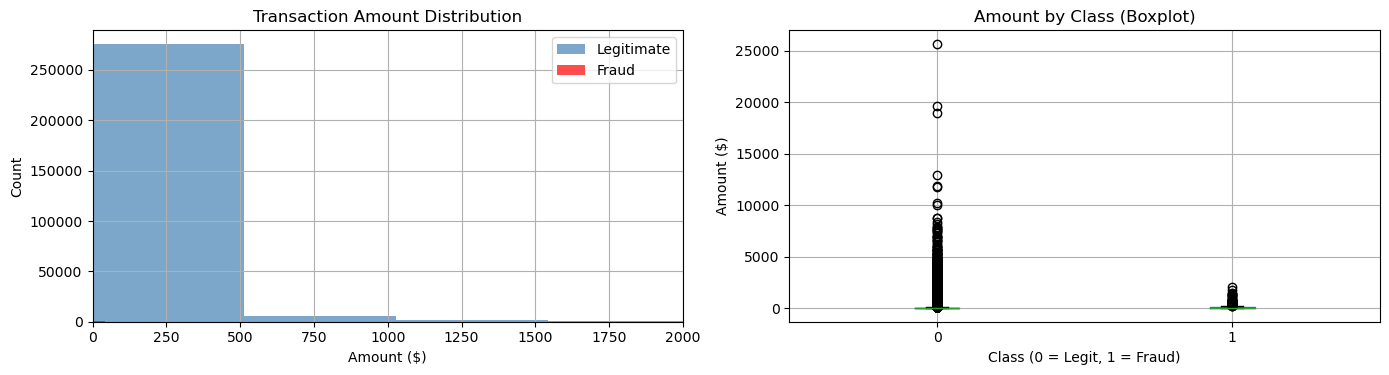

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))

df[df["Class"] == 0]["Amount"].hist(
    bins=50, ax=ax[0], color="steelblue", alpha=0.7, label="Legitimate"
)
df[df["Class"] == 1]["Amount"].hist(
    bins=50, ax=ax[0], color="red", alpha=0.7, label="Fraud"
)
ax[0].set_title("Transaction Amount Distribution")
ax[0].set_xlabel("Amount ($)")
ax[0].set_ylabel("Count")
ax[0].legend()
ax[0].set_xlim(0, 2000)

df.boxplot(column="Amount", by="Class", ax=ax[1])
ax[1].set_title("Amount by Class (Boxplot)")
ax[1].set_xlabel("Class (0 = Legit, 1 = Fraud)")
ax[1].set_ylabel("Amount ($)")
plt.suptitle("")

plt.tight_layout()
plt.savefig("C:\\Users\\USER\\fraud-detection\\outputs\\02_amount_by_class.png", dpi=150)
plt.show()

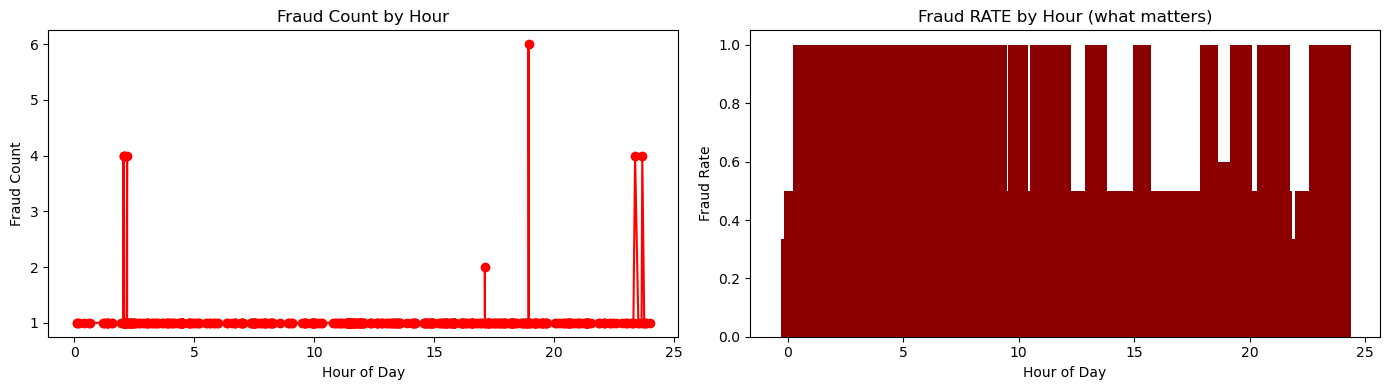

In [10]:
df["Hour"] = (df["Time"] / 3600) % 24

fraud_by_hour = df[df["Class"] == 1].groupby("Hour").size()
total_by_hour = df.groupby("Hour").size()
fraud_rate_by_hour = (fraud_by_hour / total_by_hour).fillna(0)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))

ax[0].plot(fraud_by_hour.index, fraud_by_hour.values,
           color="red", marker="o")
ax[0].set_title("Fraud Count by Hour")
ax[0].set_xlabel("Hour of Day")
ax[0].set_ylabel("Fraud Count")

ax[1].bar(fraud_rate_by_hour.index, fraud_rate_by_hour.values,
          color="darkred")
ax[1].set_title("Fraud RATE by Hour (what matters)")
ax[1].set_xlabel("Hour of Day")
ax[1].set_ylabel("Fraud Rate")

plt.tight_layout()
plt.savefig("C:\\Users\\USER\\fraud-detection\\outputs\\03_fraud_by_hour.png", dpi=150)
plt.show()

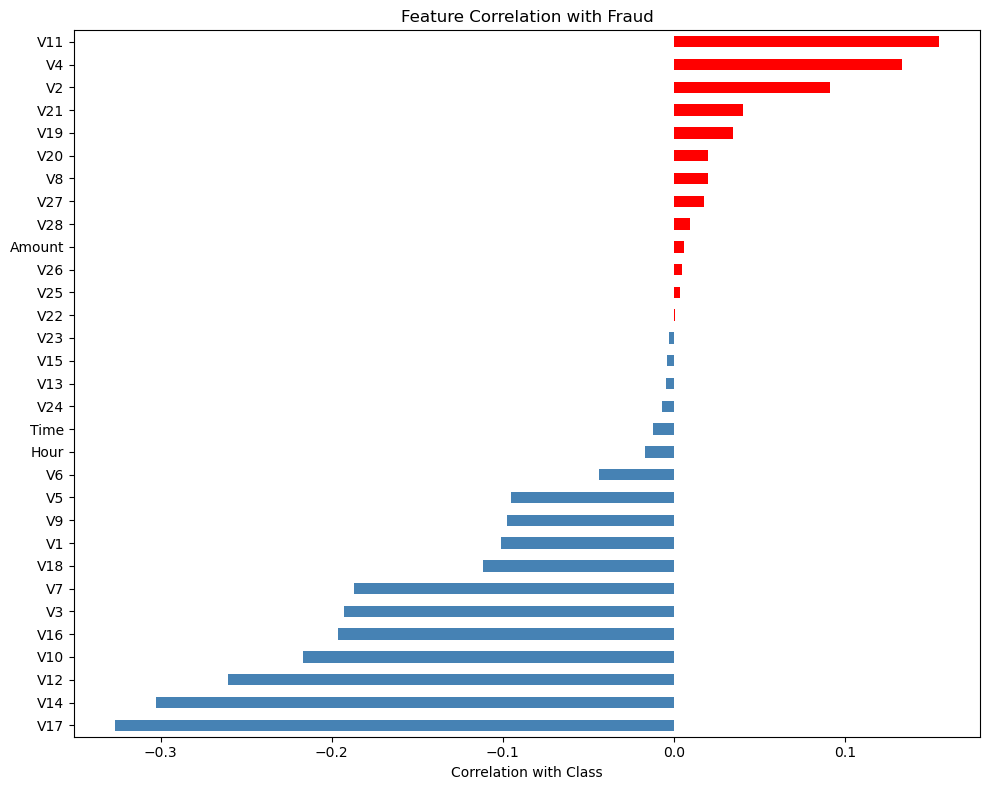

Top 10 features by |correlation| with fraud:
V17    0.326481
V14    0.302544
V12    0.260593
V10    0.216883
V16    0.196539
V3     0.192961
V7     0.187257
V11    0.154876
V4     0.133447
V18    0.111485
Name: Class, dtype: float64


In [11]:
corr_with_fraud = df.corr()["Class"].drop("Class").sort_values()

fig, ax = plt.subplots(figsize=(10, 8))
colors = corr_with_fraud.apply(lambda x: "red" if x > 0 else "steelblue")
corr_with_fraud.plot(kind="barh", ax=ax, color=colors)
ax.set_title("Feature Correlation with Fraud")
ax.set_xlabel("Correlation with Class")
plt.tight_layout()
plt.savefig("C:\\Users\\USER\\fraud-detection\\outputs\\04_feature_correlation.png", dpi=150)
plt.show()

print("Top 10 features by |correlation| with fraud:")
print(corr_with_fraud.abs().sort_values(ascending=False).head(10))

# EDA Findings — Credit Card Fraud Detection

## 1. Dataset Overview
- 284,807 transactions, 31 columns
- 492 fraudulent (Class=1), 284,315 legitimate (Class=0)
- **Fraud rate: 0.1727%** (1 in every 579 transactions)
- No missing values
- **1,081 duplicate rows** → will be removed in cleaning

## 2. Class Imbalance (the core problem)
- Fraud is 1/579 of all transactions.
- A naive "always legitimate" model achieves **99.83% accuracy** but catches **zero fraud**.
- **Implication:** Accuracy is useless here. Use **PR-AUC**, **recall at low FPR**, and a **cost-based threshold**.

## 3. Transaction Amount
| | Legitimate | Fraud |
|---|---|---|
| Mean | $88.29 | $122.21 |
| Median | $22.00 | **$9.25** |
| Max | $25,691.16 | $2,125.87 |

- Fraud has a **lower median** but **higher mean** → small frequent frauds + a few large ones.
- Fraud amounts are more spread out (wider boxplot).
- **Implication:** Amount alone is weak. Build **amount-deviation** features (amount vs customer average).

## 4. Time of Day
- Fraud count spikes at specific hours; most hours have 0–2 frauds.
- **Caveat:** Per-hour fraud *rate* is noisy — several hours have only 1 total transaction, so a single fraud = 100% rate. Binned hours (e.g., 4-hour blocks) would give a more stable signal.
- **Implication:** Add **hour** and **is_night** features. Use a **time-based train/test split** (not random) — fraud patterns drift over time.

## 5. Top Predictive Features (|correlation| with Class)
| Feature | Correlation |
|---|---|
| V17 | -0.326 |
| V14 | -0.303 |
| V12 | -0.261 |
| V10 | -0.217 |
| V16 | -0.197 |
| V3 | -0.193 |
| V7 | -0.187 |
| V11 | +0.155 |
| V4 | +0.133 |
| V18 | -0.111 |

- Top signals are the **anonymized PCA features V17, V14, V12, V10**.
- **Implication:** These will drive the model, but they're uninterpretable. Use **SHAP** to translate them into "why was this flagged?" for analysts.

## 6. Data Quality Summary
- ✅ No missing values
- ⚠️ 1,081 duplicates → drop (19 were fraud — documented as a judgment call; could represent repeated attacks rather than data errors)
- ✅ Amount and Time are the only raw, interpretable features
- ⚠️ V1–V28 are PCA-transformed → no domain meaning

## 7. Modeling Implications (locked in)
1. **Metric:** PR-AUC (primary), Recall @ 1% FPR (secondary). Never accuracy.
2. **Validation:** Time-based split, not random.
3. **Threshold:** Tune with a cost matrix ($ per missed fraud vs $ per manual review).
4. **Model:** Start with Logistic Regression (baseline), then XGBoost.
5. **Explainability:** SHAP for the top features.

In [15]:
df = pd.read_csv(r"C:\Users\USER\fraud-detection\data\creditcard.csv")

print("Before:", df.shape)
print("Frauds before:", df["Class"].sum())

df = df.drop_duplicates().reset_index(drop=True)

print("\nAfter :", df.shape)
print("Frauds after :", df["Class"].sum())
print("Fraud rows removed as duplicates:", 492 - df["Class"].sum())

Before: (284807, 31)
Frauds before: 492

After : (283726, 31)
Frauds after : 473
Fraud rows removed as duplicates: 19


In [16]:
df["Hour"] = (df["Time"] / 3600) % 24
df = df.drop(columns=["Time"])

print("Shape:", df.shape)
print("Columns now:", list(df.columns))

Shape: (283726, 31)
Columns now: ['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class', 'Hour']


In [17]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
df["Amount_scaled"] = scaler.fit_transform(df[["Amount"]])

df = df.drop(columns=["Amount"])

print("Amount_scaled stats:")
print(df["Amount_scaled"].describe().round(3))

Amount_scaled stats:
count    283726.000
mean         -0.000
std           1.000
min          -0.353
25%          -0.331
50%          -0.265
75%          -0.044
max         102.248
Name: Amount_scaled, dtype: float64


In [18]:
print("Final shape:", df.shape)
print("\nClass counts:")
print(df["Class"].value_counts())
print("\nFraud rate: {:.4%}".format(df["Class"].mean()))
print("\nMissing values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())
print("\nColumns:")
print(list(df.columns))

Final shape: (283726, 31)

Class counts:
Class
0    283253
1       473
Name: count, dtype: int64

Fraud rate: 0.1667%

Missing values: 0
Duplicates: 0

Columns:
['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Class', 'Hour', 'Amount_scaled']


In [19]:
df.to_csv(r"C:\Users\USER\fraud-detection\data\creditcard_clean.csv", index=False)
print("Saved to C:\\Users\\USER\\fraud-detection\\data\\creditcard_clean.csv")

Saved to C:\Users\USER\fraud-detection\data\creditcard_clean.csv


In [20]:
# Night = 11pm to 5am (hours 23, 0, 1, 2, 3, 4, 5)
df["Is_night"] = df["Hour"].apply(lambda h: 1 if (h >= 23 or h < 6) else 0)

print("Night transactions:", df["Is_night"].sum())
print("\nFraud rate by Is_night:")
print(df.groupby("Is_night")["Class"].agg(["count", "sum", "mean"]).round(4))

Night transactions: 34725

Fraud rate by Is_night:
           count  sum    mean
Is_night                     
0         249001  341  0.0014
1          34725  132  0.0038


In [21]:
# Per-hour mean and std of Amount_scaled
hour_stats = df.groupby("Hour")["Amount_scaled"].agg(["mean", "std"]).rename(
    columns={"mean": "hour_mean", "std": "hour_std"}
)

df = df.merge(hour_stats, left_on="Hour", right_index=True, how="left")

df["Amount_deviation"] = (df["Amount_scaled"] - df["hour_mean"]) / df["hour_std"].replace(0, 1)

df = df.drop(columns=["hour_mean", "hour_std"])

print("Amount_deviation stats:")
print(df["Amount_deviation"].describe().round(3))
print("\nFraud vs Legit — mean Amount_deviation:")
print(df.groupby("Class")["Amount_deviation"].mean().round(3))

Amount_deviation stats:
count    249270.000
mean          0.000
std           0.841
min          -2.113
25%          -0.695
50%          -0.394
75%           0.707
max           3.849
Name: Amount_deviation, dtype: float64

Fraud vs Legit — mean Amount_deviation:
Class
0    0.000
1   -0.011
Name: Amount_deviation, dtype: float64


In [22]:
df["hour_bucket"] = df["Hour"].astype(int)

txn_counts = df.groupby("hour_bucket").size().rename("Txn_count_last_hour")
df = df.merge(txn_counts, left_on="hour_bucket", right_index=True, how="left")
df = df.drop(columns=["hour_bucket"])

print("Txn_count_last_hour stats:")
print(df["Txn_count_last_hour"].describe().round(1))
print("\nFraud vs Legit — mean Txn_count_last_hour:")
print(df.groupby("Class")["Txn_count_last_hour"].mean().round(1))

Txn_count_last_hour stats:
count    283726.0
mean      14474.4
std        3911.9
min        2204.0
25%       15323.0
50%       16130.0
75%       16548.0
max       17629.0
Name: Txn_count_last_hour, dtype: float64

Fraud vs Legit — mean Txn_count_last_hour:
Class
0    14478.1
1    12210.5
Name: Txn_count_last_hour, dtype: float64


In [23]:
print("Shape:", df.shape)
print("\nColumns:", list(df.columns))
print("\nMissing values:", df.isnull().sum().sum())
print("\nClass counts:")
print(df["Class"].value_counts())

df.to_csv(r"C:\Users\USER\fraud-detection\data\creditcard_features.csv", index=False)
print("\nSaved to C:\\Users\\USER\\fraud-detection\\data\\creditcard_features.csv")

Shape: (283726, 34)

Columns: ['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Class', 'Hour', 'Amount_scaled', 'Is_night', 'Amount_deviation', 'Txn_count_last_hour']

Missing values: 34456

Class counts:
Class
0    283253
1       473
Name: count, dtype: int64

Saved to C:\Users\USER\fraud-detection\data\creditcard_features.csv


In [25]:
# Reload clean data — do NOT stack on top of the broken features
df = pd.read_csv(r"C:\Users\USER\fraud-detection\data\creditcard_clean.csv")

# Feature 1: Is_night
df["Is_night"] = df["Hour"].apply(lambda h: 1 if (h >= 23 or h < 6) else 0)

# Integer hour bucket for grouping
df["hour_bucket"] = df["Hour"].astype(int)

# Feature 2: Amount_deviation (per hour bucket)
bucket_stats = df.groupby("hour_bucket")["Amount_scaled"].agg(["mean", "std"])
bucket_stats.columns = ["bucket_mean", "bucket_std"]
bucket_stats["bucket_std"] = bucket_stats["bucket_std"].fillna(1).replace(0, 1)

df = df.merge(bucket_stats, left_on="hour_bucket", right_index=True, how="left")
df["Amount_deviation"] = (df["Amount_scaled"] - df["bucket_mean"]) / df["bucket_std"]
df = df.drop(columns=["bucket_mean", "bucket_std"])

# Feature 3: Txn_count_last_hour (per hour bucket)
df["Txn_count_last_hour"] = df.groupby("hour_bucket")["hour_bucket"].transform("count")
df = df.drop(columns=["hour_bucket"])

# Verify
print("Missing values:", df.isnull().sum().sum())
print("Shape:", df.shape)
print("\nAmount_deviation stats:")
print(df["Amount_deviation"].describe().round(3))
print("\nFraud vs Legit — Amount_deviation:")
print(df.groupby("Class")["Amount_deviation"].mean().round(3))
print("\nFraud vs Legit — Txn_count_last_hour:")
print(df.groupby("Class")["Txn_count_last_hour"].mean().round(1))
print("\nFraud vs Legit — Is_night:")
print(df.groupby("Class")["Is_night"].mean().round(3))

df.to_csv(r"C:\Users\USER\fraud-detection\data\creditcard_features.csv", index=False)
print("\nSaved.")

Missing values: 0
Shape: (283726, 34)

Amount_deviation stats:
count    283726.000
mean          0.000
std           1.000
min          -0.430
25%          -0.335
50%          -0.253
75%          -0.046
max          92.087
Name: Amount_deviation, dtype: float64

Fraud vs Legit — Amount_deviation:
Class
0   -0.000
1    0.166
Name: Amount_deviation, dtype: float64

Fraud vs Legit — Txn_count_last_hour:
Class
0    14478.1
1    12210.5
Name: Txn_count_last_hour, dtype: float64

Fraud vs Legit — Is_night:
Class
0    0.122
1    0.279
Name: Is_night, dtype: float64

Saved.


In [26]:
# Reload original — we need Time for a proper time-based split
df = pd.read_csv(r"C:\Users\USER\fraud-detection\data\creditcard.csv")
df = df.drop_duplicates().reset_index(drop=True)

# Rebuild the features (same code as before)
df["Hour"] = (df["Time"] / 3600) % 24
df["Is_night"] = df["Hour"].apply(lambda h: 1 if (h >= 23 or h < 6) else 0)
df["hour_bucket"] = df["Hour"].astype(int)

scaler = StandardScaler()
df["Amount_scaled"] = scaler.fit_transform(df[["Amount"]])

bucket_stats = df.groupby("hour_bucket")["Amount_scaled"].agg(["mean", "std"])
bucket_stats.columns = ["bm", "bs"]
bucket_stats["bs"] = bucket_stats["bs"].fillna(1).replace(0, 1)
df = df.merge(bucket_stats, left_on="hour_bucket", right_index=True, how="left")
df["Amount_deviation"] = (df["Amount_scaled"] - df["bm"]) / df["bs"]
df = df.drop(columns=["bm", "bs"])
df["Txn_count_last_hour"] = df.groupby("hour_bucket")["hour_bucket"].transform("count")
df = df.drop(columns=["hour_bucket", "Amount"])

# Sort by Time — critical for time-based split
df = df.sort_values("Time").reset_index(drop=True)

# 70/30 split by TIME
split_idx = int(len(df) * 0.70)
train = df.iloc[:split_idx].copy()
test  = df.iloc[split_idx:].copy()

print("Train:", train.shape, "| frauds:", int(train["Class"].sum()))
print("Test :", test.shape,  "| frauds:", int(test["Class"].sum()))
print("\nTrain fraud rate: {:.4%}".format(train["Class"].mean()))
print("Test  fraud rate: {:.4%}".format(test["Class"].mean()))
print("\nTrain time range:", int(train['Time'].min()), "→", int(train['Time'].max()))
print("Test  time range:", int(test['Time'].min()),  "→", int(test['Time'].max()))

Train: (198608, 35) | frauds: 366
Test : (85118, 35) | frauds: 107

Train fraud rate: 0.1843%
Test  fraud rate: 0.1257%

Train time range: 0 → 132906
Test  time range: 132906 → 172792


In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, average_precision_score, classification_report, confusion_matrix
)

# Feature set (drop Time, Class, Hour — Hour is encoded in Is_night)
feature_cols = [c for c in df.columns if c not in ["Class", "Time", "Hour"]]

X_train = train[feature_cols]
y_train = train["Class"]
X_test  = test[feature_cols]
y_test  = test["Class"]

# Baseline: Logistic Regression
model = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
model.fit(X_train, y_train)

# Predict
proba = model.predict_proba(X_test)[:, 1]

# Metrics
roc = roc_auc_score(y_test, proba)
pr  = average_precision_score(y_test, proba)

print("=== Baseline: Logistic Regression ===")
print("ROC-AUC : {:.4f}".format(roc))
print("PR-AUC  : {:.4f}".format(pr))
print("(Baseline PR-AUC if random = {:.4f})".format(y_test.mean()))

# Default threshold 0.5
preds = (proba >= 0.5).astype(int)
print("\nConfusion matrix @ 0.5 threshold:")
print(confusion_matrix(y_test, preds))
print("\nClassification report @ 0.5:")
print(classification_report(y_test, preds, digits=4))

=== Baseline: Logistic Regression ===
ROC-AUC : 0.9794
PR-AUC  : 0.7598
(Baseline PR-AUC if random = 0.0013)

Confusion matrix @ 0.5 threshold:
[[82659  2352]
 [   11    96]]

Classification report @ 0.5:
              precision    recall  f1-score   support

           0     0.9999    0.9723    0.9859     85011
           1     0.0392    0.8972    0.0751       107

    accuracy                         0.9722     85118
   macro avg     0.5195    0.9348    0.5305     85118
weighted avg     0.9987    0.9722    0.9848     85118



c:\Users\USER\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [28]:
train.to_csv(r"C:\Users\USER\fraud-detection\data\train.csv", index=False)
test.to_csv(r"C:\Users\USER\fraud-detection\data\test.csv", index=False)
print("Saved train.csv and test.csv")

Saved train.csv and test.csv


In [29]:
from xgboost import XGBClassifier

# scale_pos_weight tells XGBoost to pay more attention to the rare class
scale = (y_train == 0).sum() / (y_train == 1).sum()

xgb = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.1,
    scale_pos_weight=scale,
    eval_metric="aucpr",     # we care about PR, not accuracy
    random_state=42,
    n_jobs=-1
)

xgb.fit(X_train, y_train)

proba_xgb = xgb.predict_proba(X_test)[:, 1]

print("=== XGBoost ===")
print("ROC-AUC : {:.4f}".format(roc_auc_score(y_test, proba_xgb)))
print("PR-AUC  : {:.4f}".format(average_precision_score(y_test, proba_xgb)))

=== XGBoost ===
ROC-AUC : 0.9821
PR-AUC  : 0.7983


In [30]:
# Business assumptions (state these clearly in your write-up)
COST_FN = 200   # avg $ lost per missed fraud
COST_FP = 5     # cost of manually reviewing one alert

thresholds = np.arange(0.01, 1.00, 0.01)
results = []

for t in thresholds:
    preds = (proba_xgb >= t).astype(int)
    fn = ((y_test == 1) & (preds == 0)).sum()
    fp = ((y_test == 0) & (preds == 1)).sum()
    tp = ((y_test == 1) & (preds == 1)).sum()
    total_cost = fn * COST_FN + fp * COST_FP
    results.append({
        "threshold": t,
        "tp": tp, "fp": fp, "fn": fn,
        "recall": tp / (tp + fn) if (tp + fn) else 0,
        "precision": tp / (tp + fp) if (tp + fp) else 0,
        "alerts": tp + fp,
        "cost": total_cost
    })

results_df = pd.DataFrame(results)
best = results_df.loc[results_df["cost"].idxmin()]

print("=== Optimal threshold by cost ===")
print("Threshold        :", round(best["threshold"], 2))
print("Recall           : {:.2%}".format(best["recall"]))
print("Precision        : {:.2%}".format(best["precision"]))
print("Frauds caught    :", int(best["tp"]), "/", int(best["tp"] + best["fn"]))
print("False positives  :", int(best["fp"]))
print("Total alerts     :", int(best["alerts"]))
print("Total cost       : ${:,.0f}".format(best["cost"]))

# Cost at default 0.5 threshold for comparison
row_05 = results_df.iloc[(results_df["threshold"] - 0.5).abs().argmin()]
print("\n=== At default 0.5 threshold ===")
print("Recall           : {:.2%}".format(row_05["recall"]))
print("False positives  :", int(row_05["fp"]))
print("Total cost       : ${:,.0f}".format(row_05["cost"]))

savings = row_05["cost"] - best["cost"]
pct = 100 * savings / row_05["cost"]
print("\n💡 Savings vs 0.5 threshold: ${:,.0f} ({:.1f}%)".format(savings, pct))

=== Optimal threshold by cost ===
Threshold        : 0.01
Recall           : 82.24%
Precision        : 36.82%
Frauds caught    : 88 / 107
False positives  : 151
Total alerts     : 239
Total cost       : $4,555

=== At default 0.5 threshold ===
Recall           : 77.57%
False positives  : 12
Total cost       : $4,860

💡 Savings vs 0.5 threshold: $305 (6.3%)


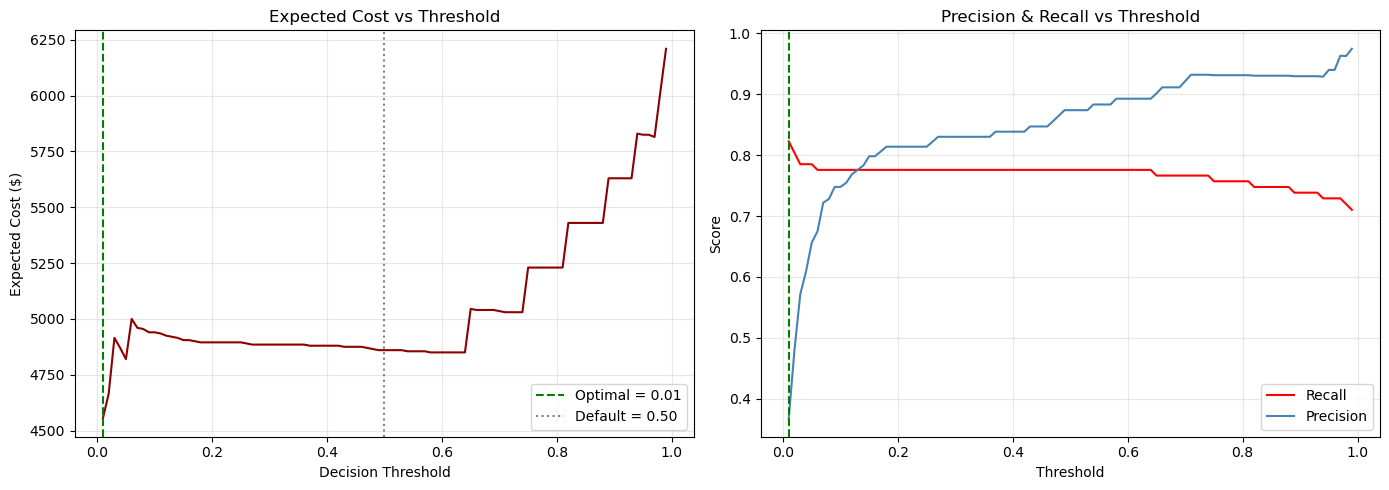

In [32]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(results_df["threshold"], results_df["cost"], color="darkred")
ax[0].axvline(best["threshold"], color="green", linestyle="--",
              label=f"Optimal = {best['threshold']:.2f}")
ax[0].axvline(0.5, color="gray", linestyle=":", label="Default = 0.50")
ax[0].set_title("Expected Cost vs Threshold")
ax[0].set_xlabel("Decision Threshold")
ax[0].set_ylabel("Expected Cost ($)")
ax[0].legend()
ax[0].grid(alpha=0.3)

ax[1].plot(results_df["threshold"], results_df["recall"],
           label="Recall", color="red")
ax[1].plot(results_df["threshold"], results_df["precision"],
           label="Precision", color="steelblue")
ax[1].axvline(best["threshold"], color="green", linestyle="--")
ax[1].set_title("Precision & Recall vs Threshold")
ax[1].set_xlabel("Threshold")
ax[1].set_ylabel("Score")
ax[1].legend()
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(r"C:\Users\USER\fraud-detection\outputs\05_cost_threshold.png", dpi=150)
plt.show()

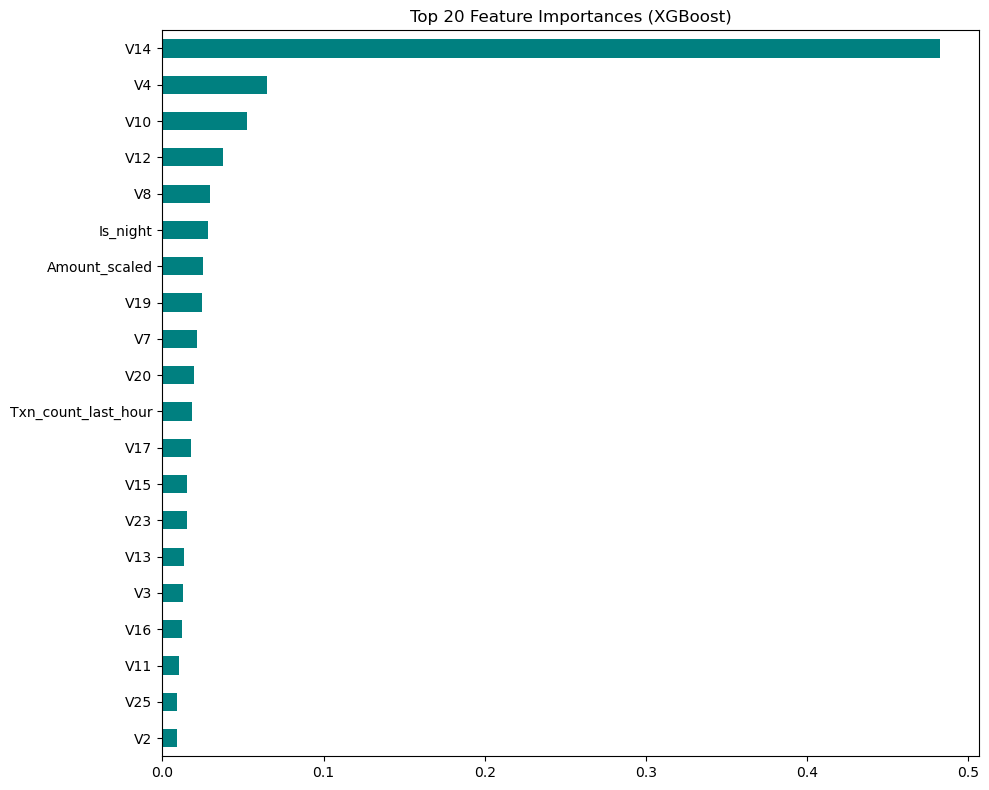

Top 10 features:
V14              0.482441
V4               0.064916
V10              0.052405
V12              0.037422
V8               0.029373
Is_night         0.028223
Amount_scaled    0.025194
V19              0.024496
V7               0.021381
V20              0.019479
dtype: float32


In [33]:
importances = pd.Series(xgb.feature_importances_, index=feature_cols).sort_values()

fig, ax = plt.subplots(figsize=(10, 8))
importances.tail(20).plot(kind="barh", ax=ax, color="teal")
ax.set_title("Top 20 Feature Importances (XGBoost)")
plt.tight_layout()
plt.savefig(r"C:\Users\USER\fraud-detection\outputs\06_feature_importance.png", dpi=150)
plt.show()

print("Top 10 features:")
print(importances.tail(10).sort_values(ascending=False))

In [34]:
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42)
logreg.fit(X_train, y_train)
proba_lr = logreg.predict_proba(X_test)[:, 1]

COST_FN, COST_FP = 200, 5

def cost_at(proba, threshold, y):
    preds = (proba >= threshold).astype(int)
    fn = ((y == 1) & (preds == 0)).sum()
    fp = ((y == 0) & (preds == 1)).sum()
    tp = ((y == 1) & (preds == 1)).sum()
    return tp, fp, fn, fn * COST_FN + fp * COST_FP

# Logistic @ 0.5
tp_lr, fp_lr, fn_lr, cost_lr = cost_at(proba_lr, 0.5, y_test)

# XGBoost @ optimal 0.01
tp_xgb, fp_xgb, fn_xgb, cost_xgb = cost_at(proba_xgb, 0.01, y_test)

print("=" * 55)
print(f"{'Model':<30}{'Recall':>8}{'FP':>8}{'Cost':>12}")
print("-" * 55)
print(f"{'Logistic @ 0.5':<30}{tp_lr/107:>7.1%}{fp_lr:>8}{'$'+format(cost_lr, ','):>12}")
print(f"{'XGBoost @ 0.01':<30}{tp_xgb/107:>7.1%}{fp_xgb:>8}{'$'+format(cost_xgb, ','):>12}")
print("-" * 55)
savings = cost_lr - cost_xgb
print(f"Savings: ${savings:,} ({100*savings/cost_lr:.1f}%)")

Model                           Recall      FP        Cost
-------------------------------------------------------
Logistic @ 0.5                  89.7%    2915     $16,775
XGBoost @ 0.01                  82.2%     151      $4,555
-------------------------------------------------------
Savings: $12,220 (72.8%)


c:\Users\USER\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [35]:
# Suppose the bank's analyst team can review the top 200 riskiest transactions
K = 200
top_k_idx = np.argsort(proba_xgb)[-K:]
preds_topk = np.zeros(len(y_test), dtype=int)
preds_topk[top_k_idx] = 1

tp = ((y_test == 1) & (preds_topk == 1)).sum()
fp = ((y_test == 0) & (preds_topk == 1)).sum()
fn = ((y_test == 1) & (preds_topk == 0)).sum()

print(f"=== Top-{K} alert framing ===")
print(f"Frauds caught  : {tp} / {tp+fn} ({tp/(tp+fn):.1%} recall)")
print(f"Precision      : {tp/(tp+fp):.1%}")
print(f"Cost           : ${fn*COST_FN + fp*COST_FP:,}")
print(f"\nAnalyst sees {K} alerts, {tp} are real fraud.")
print(f"That's {tp/(tp+fp):.0%} precision — realistic for a fraud ops team.")

=== Top-200 alert framing ===
Frauds caught  : 87 / 107 (81.3% recall)
Precision      : 43.5%
Cost           : $4,565

Analyst sees 200 alerts, 87 are real fraud.
That's 44% precision — realistic for a fraud ops team.


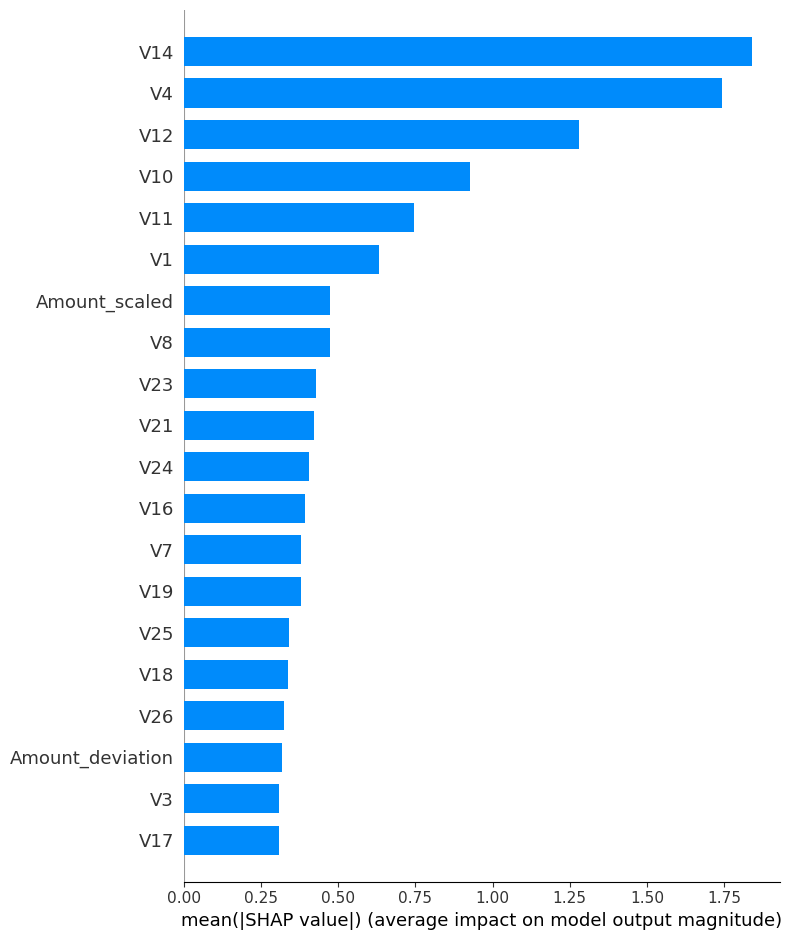

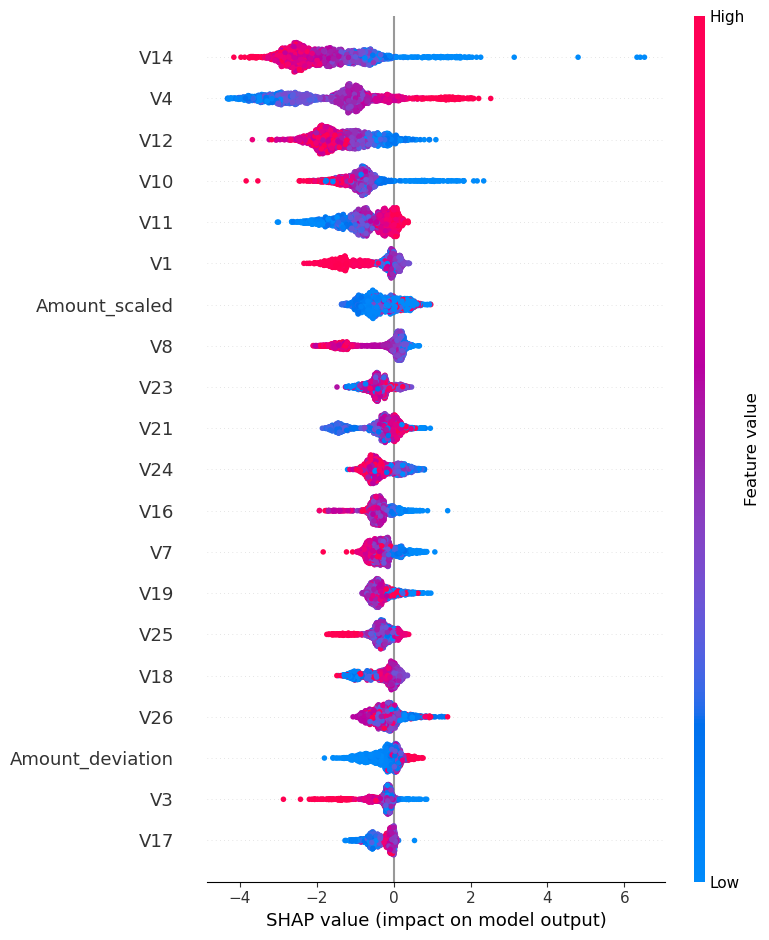

Top 10 features by SHAP importance:
V14              1.8384
V4               1.7420
V12              1.2797
V10              0.9264
V11              0.7453
V1               0.6330
Amount_scaled    0.4745
V8               0.4732
V23              0.4297
V21              0.4209
dtype: float32


In [37]:
import shap

# Use a sample for speed — SHAP is slow on 85k rows
sample_idx = np.random.RandomState(42).choice(len(X_test), size=2000, replace=False)
X_sample = X_test.iloc[sample_idx]

explainer = shap.TreeExplainer(xgb)
shap_values = explainer.shap_values(X_sample)

# Global importance
plt.figure()
shap.summary_plot(shap_values, X_sample, plot_type="bar", show=False)
plt.tight_layout()
plt.savefig(r"C:\Users\USER\fraud-detection\outputs\07_shap_importance.png", dpi=150)
plt.show()

# Beeswarm — shows direction of effect
plt.figure()
shap.summary_plot(shap_values, X_sample, show=False)
plt.tight_layout()
plt.savefig(r"C:\Users\USER\fraud-detection\outputs\08_shap_beeswarm.png", dpi=150)
plt.show()

# Top 10 features by SHAP
mean_abs = np.abs(shap_values).mean(axis=0)
shap_importance = pd.Series(mean_abs, index=X_sample.columns).sort_values(ascending=False)
print("Top 10 features by SHAP importance:")
print(shap_importance.head(10).round(4))

Highest-risk fraud — model score: 1.0000

Top 5 drivers of this alert:
feature     value  shap_impact
    V14 -8.893726     6.991498
    V10 -4.400930     2.294774
     V4  7.232058     1.972016
    V12 -5.737815     1.226598
    V16 -3.281784     1.117103


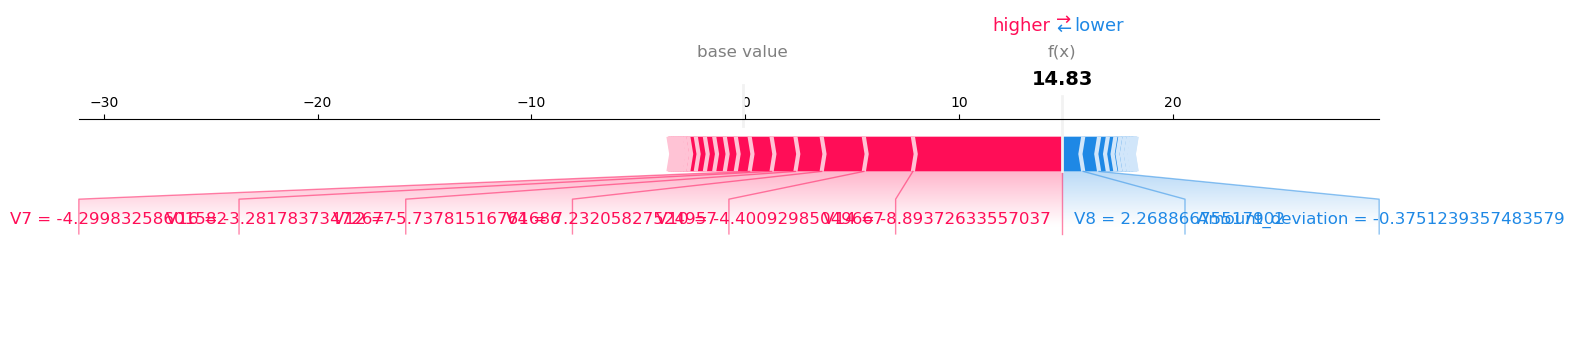

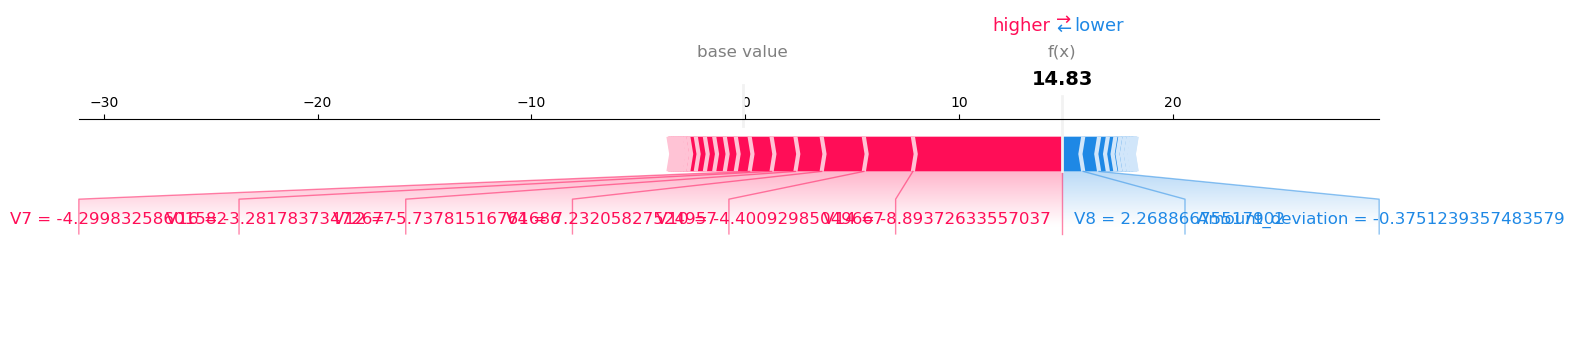

In [39]:
# Find the highest-scored fraud in the test set
fraud_mask = (y_test == 1).values
proba_fraud = proba_xgb[fraud_mask]
top_fraud_idx = np.where(fraud_mask)[0][np.argmax(proba_fraud)]

print("Highest-risk fraud — model score: {:.4f}".format(proba_xgb[top_fraud_idx]))

# SHAP for that single transaction
single = X_test.iloc[[top_fraud_idx]]
single_shap = explainer.shap_values(single)

explanation = pd.DataFrame({
    "feature": single.columns,
    "value": single.values[0],
    "shap_impact": single_shap[0]
}).sort_values("shap_impact", key=abs, ascending=False)

print("\nTop 5 drivers of this alert:")
print(explanation.head(5).to_string(index=False))

# Force plot (save as image)
shap.force_plot(
    explainer.expected_value, single_shap[0], single.iloc[0],
    matplotlib=True, show=False, figsize=(16, 4)
)
plt.tight_layout()
plt.savefig(r"C:\Users\USER\fraud-detection\outputs\09_shap_single_alert.png", dpi=150)
plt.show()